## Recomendación: Análisis

- Se interpretan los modelos: **proveedores sustitutos por categoría** y **afinidades inusuales**

- Se responde la PQ3 y se complementa la PQ1

- ¿La cautividad se explica por falta de alternativas?

### Constantes

- `N_SUST` = 5: sustitutos por proveedor

- `RANGO_P_INUSUAL`: percentil del puntaje de ALS bajo el cual una relación existente se considera inusual

- `TOP_FAMILIAS` = 8: familias UNSPSC con más proveedores que se reportan

In [1]:
N_SUST = 5
RANGO_P_INUSUAL = [1, 5, 10]
TOP_FAMILIAS = 8

### Detalle

- **Sustitutos:** para cada proveedor, los `N_SUST` de su misma familia UNSPSC 

- Con mayor coseno (`v_p · v_q`), con ALS y con contenido

- Validación: % de pares que co-participan en procesos vs. pares al azar de la misma familia

- **Afinidades inusuales:** relaciones de 2023-2024 con puntaje ALS (`u_e · v_p`) ≤ `P_INUSUAL`

### Utilidades

In [2]:
NOTEBOOK = "f_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

ERROR: Could not find a version that satisfies the requirement faiss-cpu==1.8.0 (from versions: 1.9.0.post1, 1.10.0, 1.11.0, 1.11.0.post1, 1.12.0, 1.13.0, 1.13.1, 1.13.2, 1.14.2, 1.14.3, 1.15.0, 1.15.1, 1.16.0)

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for faiss-cpu==1.8.0
Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/10 12:37:42 WARN Utils: Your hostname, Paolos-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.18.67 instead (on interface en0)
26/11/10 12:37:42 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/10 12:37:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/10 12:37:43 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Master        : local[*]
Executors     : 0
Cores totales : 8
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- Factores de ALS y perfiles de contenido en test; relaciones 2023-2024 con su puntaje

- `hechos` (familia, monto, competencia), `grafo_coparticipacion` y `features_entidad` (HHI)

In [ ]:
cfg = leer_config()
c = contexto("test", SENAL)
ent, prov = pd.read_parquet(datos_dir / "entidades"), pd.read_parquet(datos_dir / "proveedores")

prov["nombre_pub"] = np.where(prov.proveedor_key.str.startswith("PN:"), "(persona natural)", prov.nombre)
e_idx, p_idx = dict(zip(ent.entidad_key, ent.entidad_idx)), dict(zip(prov.proveedor_key, prov.proveedor_idx))
V = np.load(datos_dir / "als_proveedor.npy")
Vn = V / np.linalg.norm(V, axis=1, keepdims=True).clip(1e-9)
P = np.load(datos_dir / "vec_proveedor_test.npy")
existentes = pd.read_parquet(datos_dir / "als_existentes")

h = leer(final_dir, "hechos").where(F.col("anio").isin(PARTICIONES["test"][0]))
pares = (h.groupBy("entidad_key", "proveedor_key")
          .agg(F.avg("postor_unico").alias("postor_unico"), F.avg("es_directa").alias("es_directa"),
               F.countDistinct("familia").alias("n_familias")).toPandas())
fam_par = (h.where("familia <> 'SIN'").groupBy("entidad_key", "proveedor_key", "familia").agg(F.sum("monto_asignado").alias("m")).toPandas())
co = leer(artef_dir, "grafo_coparticipacion/aristas").select(F.substring("src", 3, 40).alias("a"), F.substring("dst", 3, 40).alias("b")).toPandas()
hhi = leer(artef_dir, "features_entidad").select("entidad_key", "hhi_proveedores", "share_top_proveedores", "n_proveedores").toPandas()
print(f"relaciones 2023-2024: {len(existentes):,} | aristas de co-participación: {len(co):,} | entidades con HHI: {len(hhi):,}")

relaciones 2023-2024: 96,022 | aristas de co-participación: 1,639,945 | entidades con HHI: 2,996


---
### **1. Sustitutos por categoría**

- Dado un proveedor, ¿qué otros ocupan el mismo lugar en el mercado?

- **ALS:** "les adjudican entidades parecidas"

- **Contenido:** "venden cosas parecidas"

- Si son sustitutos reales, deberían **competir** entre sí en los mismos procesos

In [5]:
fp = fam_par.groupby(["proveedor_key", "familia"]).m.sum().reset_index().sort_values("m", ascending=False).drop_duplicates("proveedor_key")
prov = prov.merge(fp[["proveedor_key", "familia"]], on="proveedor_key", how="left")
cat = prov[c["catalogo"] & prov.familia.notna()]
aristas = set(zip(co.a, co.b)) | set(zip(co.b, co.a))
rng = np.random.default_rng(SEED)

def sustitutos(M, ids):
    S = M[ids] @ M[ids].T
    np.fill_diagonal(S, -np.inf)
    k = min(N_SUST, len(ids) - 1)
    return ids[np.argsort(-S, axis=1)[:, :k]]

claves = prov.proveedor_key.to_numpy()
filas_s, ejemplos = [], {}
for fam, g in cat.groupby("familia"):
    ids = g.proveedor_idx.to_numpy()
    if len(ids) < N_SUST + 1:
        continue
    for nombre, M in {"als": Vn, "contenido": P}.items():
        s = sustitutos(M, ids)
        ejemplos[(fam, nombre)] = (ids, s)
        filas_s += [{"familia": fam, "metodo": nombre, "copart": (claves[a], claves[b]) in aristas} for a, fila in zip(ids, s) for b in fila]
    azar = rng.choice(ids, size=(len(ids), N_SUST))
    filas_s += [{"familia": fam, "metodo": "azar (misma familia)", "copart": (claves[a], claves[b]) in aristas}
                for a, fila in zip(ids, azar) for b in fila if a != b]
filas_s = pd.DataFrame(filas_s)
resumen_s = filas_s.groupby("metodo").agg(pares=("copart", "size"), pct_coparticipan=("copart", "mean"))
resumen_s["pct_coparticipan"] = (100 * resumen_s.pct_coparticipan).round(1)
print(f"familias con ≥ {N_SUST + 1} proveedores en el catálogo: {filas_s.familia.nunique()} | proveedores: {cat.familia.isin(filas_s.familia).sum():,}")
resumen_s

familias con ≥ 6 proveedores en el catálogo: 170 | proveedores: 9,115


,pares,pct_coparticipan
metodo,,
als,45575,33.7
azar (misma familia),44712,12.0
contenido,45575,40.3


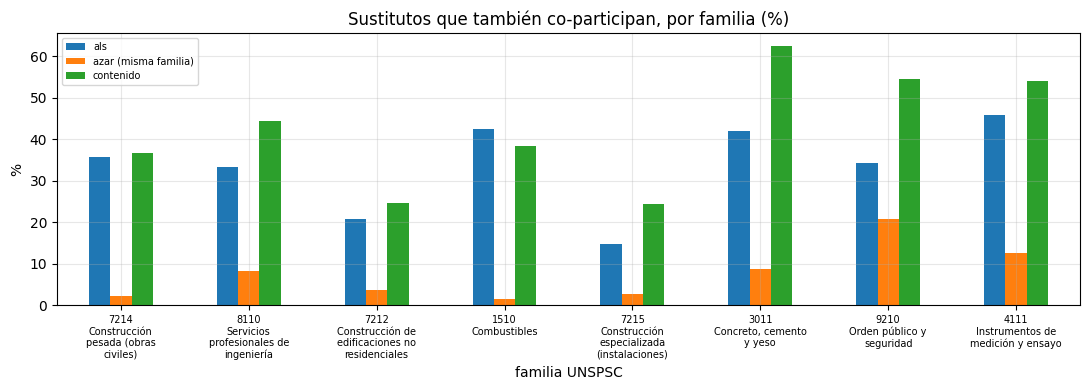

,nombre,als,azar (misma familia),contenido,proveedores
familia,,,,,
7214,Construcción pesada (obras civiles),35.8,2.3,36.6,918
8110,Servicios profesionales de ingeniería,33.4,8.3,44.5,618
7212,Construcción de edificaciones no residenciales,20.9,3.6,24.6,599
1510,Combustibles,42.5,1.5,38.3,567
7215,Construcción especializada (instalaciones),14.8,2.8,24.5,494
3011,"Concreto, cemento y yeso",42.1,8.7,62.5,343
9210,Orden público y seguridad,34.2,20.9,54.4,220
4111,Instrumentos de medición y ensayo,45.8,12.7,54.1,212


In [17]:
NOMBRES_FAMILIA = {"7214": "Construcción pesada (obras civiles)", "8110": "Servicios profesionales de ingeniería",
                   "7212": "Construcción de edificaciones no residenciales", "1510": "Combustibles",
                   "7215": "Construcción especializada (instalaciones)", "3011": "Concreto, cemento y yeso",
                   "9210": "Orden público y seguridad", "4111": "Instrumentos de medición y ensayo"}
top_f = cat.familia.value_counts().head(TOP_FAMILIAS).index
por_familia = (filas_s[filas_s.familia.isin(top_f)].groupby(["familia", "metodo"]).copart.mean().mul(100).round(1)
               .unstack().join(cat.familia.value_counts().rename("proveedores")).sort_values("proveedores", ascending=False))
por_familia.insert(0, "nombre", por_familia.index.map(lambda f: NOMBRES_FAMILIA.get(str(f), "")))
fig, ax = plt.subplots(figsize=(11, 4))
por_familia.drop(columns=["nombre", "proveedores"]).plot.bar(ax=ax, rot=0)
ax.set_xticklabels([f"{f}\n{n}" for f, n in zip(por_familia.index, por_familia.nombre.str.wrap(18))], fontsize=7)
ax.set_title("Sustitutos que también co-participan, por familia (%)"); ax.set_xlabel("familia UNSPSC"); ax.set_ylabel("%"); ax.legend(fontsize=7)
mostrar_fig("sustitutos_coparticipan")
por_familia

- **170 familias** con ≥ 6 proveedores en el catálogo (9,115 proveedores)

- **33.7%** de los sustitutos por ALS y **40.3%** por contenido también **co-participan**, contra **12.0%** al azar

- Es más marcado en obras (7214: 36% vs 2%) y combustibles (1510: 43% vs 2%)

- Los sustitutos son **competidores reales**, no solo proveedores del mismo rubro

#### a. Ejemplos

Proveedores con más entidades de dos familias grandes y sus sustitutos por ALS

In [7]:
grado = np.asarray(c["vistos"].sum(0)).ravel()
ej = []
for fam in top_f[:2]:
    ids, s = ejemplos[(fam, "als")]
    for i in np.argsort(-grado[ids])[:3]:
        a = ids[i]
        ej.append({"familia": fam, "proveedor": prov.nombre_pub[a], "entidades": int(grado[a]),
                   "sustitutos_als": " | ".join(prov.nombre_pub[b] for b in s[i][:3]),
                   "coparticipan": sum((claves[a], claves[b]) in aristas for b in s[i][:3])})
ej = pd.DataFrame(ej)
ej

,familia,proveedor,entidades,sustitutos_als,coparticipan
0,7214,SVT CONSTRUCTORES E.I.R.L.,14,SERV.DE TRANSP. Y MOVIM.DE TIERRAS EIRL. | ARES RENTAL MAQUINARIAS SOCIEDAD ...,3
1,7214,CONSTRUCTORA E INMOBILIARIA ENMANUEL & LUCIANO SOCIEDAD ANONIMA CERRADA,12,INGCONS CONTRATISTAS GENERALES E.I.R.L. | TELLUS CONTRATISTAS GENERALES S.A....,3
2,7214,ZAPATA INGENIEROS SOCIEDAD COMERCIAL DE RESPONSABILIDAD LIMITADA-ZAPATA INGE...,11,(persona natural) | R & D AMERICAN CONSTRUCTORA S.A.C. | CONSTRUCTORA PERU T...,2
3,8110,PRACTIOBRAS EMPRESA INDIVIDUAL DE RESPONSABILIDAD LIMITADA,23,GRUPO HISO S.A.C. | (persona natural) | (persona natural),0
4,8110,(persona natural),22,COPERCALS S.A.C. | (persona natural) | (persona natural),3
5,8110,WARI CONSULTORES E.I.R.L.,16,(persona natural) | ZEHUAS PERU S.A.C. | (persona natural),2


- Construcción (7214) y consultoría de obras (8110)

- Sustitutos con más clientes suelen ser otros contratistas con los que **ya compiten**

---
### **2. Afinidades inusuales**

- Relaciones **existentes** (2023-2024) con puntaje de ALS muy bajo

- Por monto, competencia (`postor_unico`, `es_directa`) y por su parecido de contenido

- Inusual ≠ irregular: puede ser un proveedor especializado o una compra excepcional

In [8]:
E_cont = np.load(datos_dir / "vec_entidad_test.npy")
ex = (existentes.merge(ent[["entidad_idx", "entidad_key", "nombre", "region"]], on="entidad_idx")
                .merge(prov[["proveedor_idx", "proveedor_key", "nombre_pub", "familia"]], on="proveedor_idx")
                .merge(pares, on=["entidad_key", "proveedor_key"], how="left"))
ex["coseno_contenido"] = np.einsum("ij,ij->i", E_cont[ex.entidad_idx], P[ex.proveedor_idx])
ex["grado_proveedor"] = grado[ex.proveedor_idx]

def describir(m):
    return {"relaciones": int(m.sum()), "pct_monto": round(100 * ex.monto[m].sum() / ex.monto.sum(), 1),
            "monto_mediano": round(ex.monto[m].median()), "postor_unico": round(ex.postor_unico[m].mean(), 3),
            "es_directa": round(ex.es_directa[m].mean(), 3), "coseno_contenido": round(ex.coseno_contenido[m].median(), 3),
            "pct_prov_una_entidad": round(100 * (ex.grado_proveedor[m] == 1).mean(), 1), "pct_consorcio": round(100 * ex.proveedor_key[m].str.startswith("CONS:").mean(), 1)}

inusual = pd.DataFrame([{"grupo": f"p ≤ {t}%", **describir(ex.percentil <= t / 100)} for t in RANGO_P_INUSUAL] +
                       [{"grupo": "resto", **describir(ex.percentil > P_INUSUAL / 100)}, {"grupo": "todas", **describir(ex.percentil >= 0)}])
inusual

,grupo,relaciones,pct_monto,monto_mediano,postor_unico,es_directa,coseno_contenido,pct_prov_una_entidad,pct_consorcio
0,p ≤ 1%,965,0.6,217851,0.073,0.070,0.827,92.3,64.9
1,p ≤ 5%,4805,3.0,188100,0.063,0.053,0.658,81.4,54.6
2,p ≤ 10%,9604,5.5,188832,0.070,0.063,0.620,76.7,50.6
3,resto,91217,97.0,209800,0.118,0.073,0.447,52.2,26.9
4,todas,96022,100.0,208178,0.115,0.072,0.459,53.6,28.3


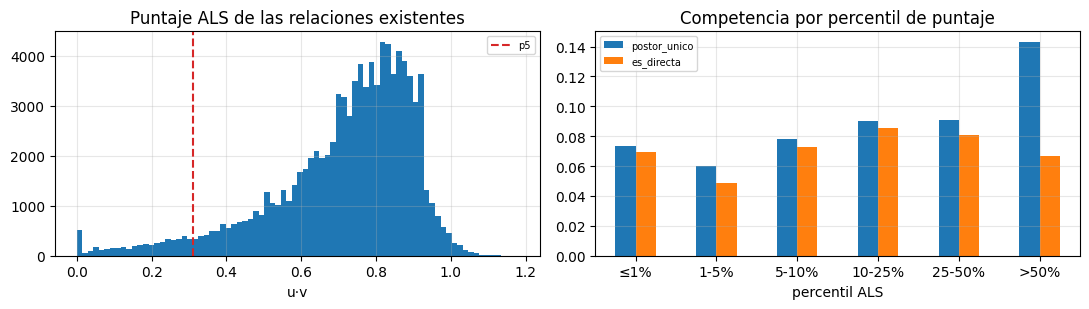

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(ex.score, bins=80); ax[0].axvline(ex.score.quantile(P_INUSUAL / 100), color="tab:red", ls="--", label=f"p{P_INUSUAL}")
ax[0].set_title("Puntaje ALS de las relaciones existentes"); ax[0].set_xlabel("u·v"); ax[0].legend(fontsize=7)
b = pd.cut(ex.percentil, [0, .01, .05, .1, .25, .5, 1], labels=["≤1%", "1-5%", "5-10%", "10-25%", "25-50%", ">50%"])
ex.groupby(b, observed=True)[["postor_unico", "es_directa"]].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Competencia por percentil de puntaje"); ax[1].set_xlabel("percentil ALS"); ax[1].legend(fontsize=7)
mostrar_fig("afinidades_inusuales")

- **5% más bajo (4,805 relaciones, 3.0% del monto):** 

- 81% con un proveedor de una sola entidad y 55% consorcios (vs. 52% y 27% en el resto)

- **Menos** postor único (6.3% vs 11.8%) y directa (5.3% vs 7.3%) que el resto

- Coseno de contenido **alto** (0.66 vs 0.45): el proveedor solo le vendió a esa entidad

- El perfil es parecido con 5% y 10%; se fija `P_INUSUAL = 5`

- Una **afinidad inusual** típica: un consorcio armado para **una obra** de una municipalidad

In [10]:
casos_inusuales = (ex[ex.percentil <= P_INUSUAL / 100].nlargest(10, "monto")
                   [["nombre", "region", "nombre_pub", "familia", "n_adj", "monto", "percentil", "coseno_contenido", "postor_unico", "es_directa"]]
                   .rename(columns={"nombre": "entidad", "nombre_pub": "proveedor"}).round(3))
casos_inusuales

,entidad,region,proveedor,familia,n_adj,monto,percentil,coseno_contenido,postor_unico,es_directa
53554,GOBIERNO REGIONAL DE PIURA - PROYECTO ESPECIAL DE IRRIGACION HIDROENERGETICO...,PIURA,CONSORCIO LIMA SUR,7214,1,1.082078e+08,0.024,0.780,0.0,0.0
46420,MUNICIPALIDAD DISTRITAL DE PARDO MIGUEL - NARANJOS,SAN MARTIN,CONSORCIO ESMERALDA,7214,1,7.922944e+07,0.036,0.466,0.0,0.0
95127,MUNICIPALIDAD DISTRITAL DE SAN FERNANDO,SAN MARTIN,CONSORCIO EJECUTOR SANFER,7214,1,4.985000e+07,0.007,0.773,0.0,0.0
41573,MUNICIPALIDAD DISTRITAL DE PULAN,CAJAMARCA,CONSORCIO VIAL LA PALMA,7214,1,4.664671e+07,0.040,0.742,0.0,1.0
5905,MUNICIPALIDAD DISTRITAL DE QUINJALCA,AMAZONAS,CONSORCIO EJECUTOR L&R,7214,1,4.240600e+07,0.012,0.853,0.0,0.0
7843,MUNICIPALIDAD PROVINCIAL DEL PUTUMAYO,LORETO,CONSORCIO PADRE MEDARDO,7212,1,3.747000e+07,0.010,0.845,0.0,0.0
21360,MUNICIPALIDAD DISTRITAL DE PINTO RECODO,SAN MARTIN,CONSORCIO EJECUTOR FORTALEZA,7214,1,3.593604e+07,0.038,0.653,0.0,0.0
17971,MUNICIPALIDAD DISTRITAL DE AWAJUN,SAN MARTIN,CONSORCIO CONFIANZA,7214,1,3.484350e+07,0.044,0.625,0.0,0.0
76440,MUNICIPALIDAD DISTRITAL DE CURPAHUASI,APURIMAC,CONSORCIO GRAU,7212,1,3.164858e+07,0.020,0.719,0.0,0.0
72613,MUNICIPALIDAD DISTRITAL DE URACA - CORIRE,AREQUIPA,CONSORCIO COSMOS,7212,1,2.843872e+07,0.026,0.697,0.0,0.0


- Las 10 de mayor monto son **obras viales y de riego (7214, 7212)**

- De S/28-108M en municipalidades y proyectos regionales

- Todas con consorcios de una sola adjudicación y casi siempre con competencia (postor único = 0)

- Son relaciones que el patrón general no explica por ser **únicas**, no por ser irregulares

---
### **3. PQ1: ¿la cautividad se explica por falta de alternativas?**

- **Cautiva:** HHI de proveedores ≥ `UMBRAL_HHI` (0.25)

- **Mercado de la entidad:** la familia de su relación de mayor monto

- **Alternativas:** proveedores que ganaron en esa familia y en la región de la entidad (2023-2024)

- **Alternativas recomendadas:** candidatos del híbrido (top-`N_CAND`) de esa misma familia

In [11]:
fam_ent = fam_par.sort_values("m", ascending=False).drop_duplicates("entidad_key")[["entidad_key", "proveedor_key", "familia"]]
reg_p = (fam_par.merge(ent[["entidad_key", "region"]], on="entidad_key").groupby(["familia", "region"]).proveedor_key.apply(set).to_dict())
hib = leer_recs("hibrido_test").merge(prov[["proveedor_idx", "familia"]], on="proveedor_idx")
hib_fam = hib.groupby(["entidad_idx", "familia"]).size().to_dict()

alt = fam_ent.merge(ent[["entidad_key", "entidad_idx", "region"]], on="entidad_key").merge(hhi, on="entidad_key")
alt["alternativas_mercado"] = [len(reg_p.get((f, r), set()) - {p}) for f, r, p in zip(alt.familia, alt.region, alt.proveedor_key)]
alt["evaluada"] = alt.entidad_idx.isin(c["pos"])
alt["alternativas_recomendadas"] = [hib_fam.get((e, f), 0) if ok else np.nan for e, f, ok in zip(alt.entidad_idx, alt.familia, alt.evaluada)]
alt["cautiva"] = (alt.hhi_proveedores >= UMBRAL_HHI).map({True: "cautiva", False: "no cautiva"})
pq1 = alt.groupby("cautiva").agg(entidades=("entidad_key", "size"), hhi_mediano=("hhi_proveedores", "median"),
                                 proveedores_mediana=("n_proveedores", "median"),
                                 alt_mercado_mediana=("alternativas_mercado", "median"),
                                 pct_sin_alt_mercado=("alternativas_mercado", lambda x: round(100 * (x == 0).mean(), 1)),
                                 evaluadas=("evaluada", "sum"),
                                 alt_recomendadas_mediana=("alternativas_recomendadas", "median"),
                                 pct_sin_alt_recomendada=("alternativas_recomendadas", lambda x: round(100 * (x.dropna() == 0).mean(), 1))).round(3)
pq1

,entidades,hhi_mediano,proveedores_mediana,alt_mercado_mediana,pct_sin_alt_mercado,evaluadas,alt_recomendadas_mediana,pct_sin_alt_recomendada
cautiva,,,,,,,,
cautiva,964,0.397,7.0,217.0,0.3,494,9.0,4.9
no cautiva,1882,0.101,35.0,248.0,0.7,1614,7.0,10.4


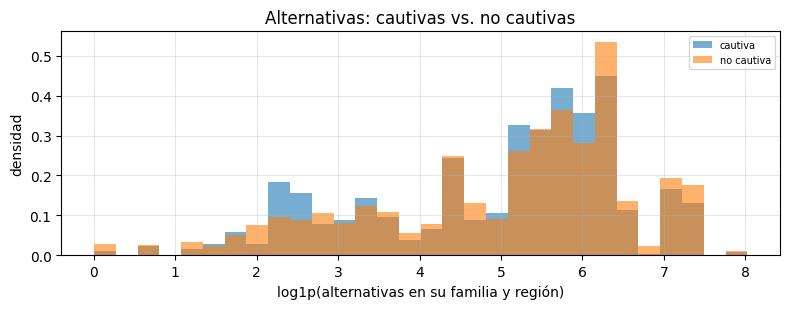

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for k_, g in alt.groupby("cautiva"):
    ax.hist(np.log1p(g.alternativas_mercado), bins=30, alpha=.6, density=True, label=k_)
ax.set_xlabel("log1p(alternativas en su familia y región)"); ax.set_ylabel("densidad"); ax.set_title("Alternativas: cautivas vs. no cautivas")
ax.legend(fontsize=7)
mostrar_fig("alternativas_cautivas")

- **964 entidades cautivas** (HHI mediano 0.40, 7 proveedores) vs 1,882 no cautivas (HHI 0.10, 35 proveedores)

- **Alternativas en su mercado:** mediana de **217** proveedores en su familia y región (248 en las no cautivas)

- **Alternativas recomendadas:** mediana de 9 en las cautivas evaluadas (7 en las no cautivas)

- **La cautividad no se explica por falta de alternativas:** casi todas tienen decenas de proveedores en su rubro y región

- La dependencia típica es de un consorcio armado para una obra grande

---
### **4. Caso concreto**

Una entidad cautiva con alternativas en su mercado: su proveedor principal y los candidatos del híbrido en esa familia

entidad: MUNICIPALIDAD DISTRITAL DE SAN JUAN DE CHACÑA (APURIMAC) | HHI 0.97 | familia 7214 | principal: CONSORCIO VIAL ENHAFA | alternativas en su mercado: 303


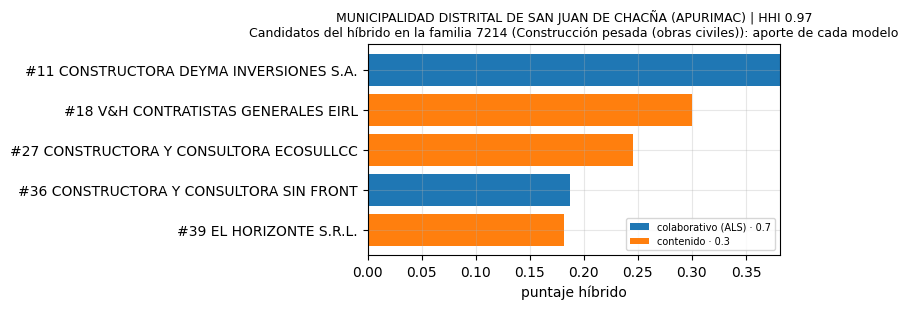

,rank,proveedor,score,s_cf,s_co
0,11,CONSTRUCTORA DEYMA INVERSIONES S.A.C.,0.382,0.545,0.000
1,18,V&H CONTRATISTAS GENERALES EIRL,0.300,0.000,1.000
2,27,CONSTRUCTORA Y CONSULTORA ECOSULLCC INGENIEROS E.I.R.L.,0.246,0.000,0.819
3,36,CONSTRUCTORA Y CONSULTORA SIN FRONTERAS EMPRESA INDIVIDUAL DE RESPONSABILIDA...,0.187,0.267,0.000
4,39,EL HORIZONTE S.R.L.,0.182,0.000,0.607


In [18]:
cand = alt[(alt.cautiva == "cautiva") & alt.evaluada & (alt.alternativas_recomendadas >= 3)].sort_values("hhi_proveedores", ascending=False)
caso = cand.iloc[0]
print(f"entidad: {ent.nombre[caso.entidad_idx]} ({caso.region}) | HHI {caso.hhi_proveedores:.2f} | familia {caso.familia} | "
      f"principal: {prov.nombre_pub[p_idx[caso.proveedor_key]]} | alternativas en su mercado: {caso.alternativas_mercado}")
caso_recs = (hib[(hib.entidad_idx == caso.entidad_idx) & (hib.familia == caso.familia)].sort_values("rank").head(5)
             .merge(prov[["proveedor_idx", "nombre_pub"]], on="proveedor_idx")[["rank", "nombre_pub", "score", "s_cf", "s_co"]]
             .rename(columns={"nombre_pub": "proveedor"}).round(3))

fig, ax = plt.subplots(figsize=(8, 3.2))
d = caso_recs.iloc[::-1]
etq = [f"#{r} {p[:35]}" for r, p in zip(d["rank"], d.proveedor)]
ax.barh(etq, W_HIBRIDO * d.s_cf, label=f"colaborativo (ALS) · {W_HIBRIDO}")
ax.barh(etq, (1 - W_HIBRIDO) * d.s_co, left=W_HIBRIDO * d.s_cf, label=f"contenido · {1 - W_HIBRIDO:.1f}")
ax.set_xlabel("puntaje híbrido")
ax.set_title(f"{ent.nombre[caso.entidad_idx]} ({caso.region}) | HHI {caso.hhi_proveedores:.2f}\n"
             f"Candidatos del híbrido en la familia {caso.familia} ({NOMBRES_FAMILIA.get(str(caso.familia), '')}): aporte de cada modelo", fontsize=9)
ax.legend(fontsize=7)
mostrar_fig("caso_cautiva")
caso_recs

- Municipalidad distrital de Apurímac con **HHI 0.97**: casi todo su monto fue a un consorcio vial

- En su mercado (construcción, 7214, en Apurímac) hay **303 proveedores** con adjudicaciones en 2023-2024

- El híbrido propone constructoras de la región: unas por entidades parecidas y otras por texto parecido

- Son **alternativas que existen en el mercado**, no una recomendación de contratarlas

---
### **5. Síntesis**

| Pregunta | Hallazgo |
|---|---|
| ¿Qué enfoque modela mejor la relación entidad–proveedor? | Híbrido ALS + contenido (w = 0.7): NDCG@10 = 0.099 en 2025, sobre user-user (0.095), ALS (0.094) y la regional (0.081) |
| ¿Qué aporta cada uno? | El colaborativo captura "quién compra a quién"; el contenido, "qué se vende", y llega a proveedores que solo ofertaron (11% de entidades con acierto vs 0.02% al azar) |
| ¿Cuánto se puede predecir? | Solo 34% de las relaciones nuevas tiene un proveedor ya visto: la cola larga y los consorcios de un uso limitan cualquier modelo |
| PQ3: ¿hay sustitutos por categoría? | Sí: 34-40% de los sustitutos de una familia compiten entre sí en procesos |
| PQ3: ¿qué relaciones son atípicas? | El 5% con menor puntaje: consorcios de una obra en municipalidades con competencia |
| PQ1: ¿la cautividad es falta de alternativas? | No: las entidades cautivas tienen una mediana de 217 proveedores en su familia y región |

---
### **6. Escritura de resultados**

In [14]:
escritos = guardar_tablas({"sustitutos_resumen": resumen_s.reset_index(), "sustitutos_por_familia": por_familia.reset_index(),
                           "sustitutos_ejemplos": ej, "afinidades_inusuales": inusual, "casos_inusuales": casos_inusuales,
                           "pq1_alternativas": pq1.reset_index(), "caso_cautiva": caso_recs})

Escrito en 03_Recomend/temp/f_analisis/: sustitutos_resumen, sustitutos_por_familia, sustitutos_ejemplos, afinidades_inusuales, casos_inusuales, pq1_alternativas, caso_cautiva


#### a. Verificación

In [15]:
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 4 figuras: afinidades_inusuales, alternativas_cautivas, caso_cautiva, sustitutos_coparticipan


---
### **8. Cerrar sesión**

In [16]:
spark.stop()